# Análisis exploratorio: COVID-19 en Estados Unidos (2020-2021)

**Fuente:** [The COVID Tracking Project](https://covidtracking.com/data/download), datos diarios por estado
(`https://api.covidtracking.com/v1/states/daily.csv`). Recoge casos, tests, hospitalizaciones y
fallecimientos de los 50 estados, el Distrito de Columbia y 5 territorios, del 13 de enero de 2020
al 7 de marzo de 2021, cuando el proyecto dejó de recopilar datos.

**Qué hacemos en este notebook**

1. Cargar los datos y revisar su estructura.
2. Limpiar: faltantes, duplicados, tipos, columnas que sobran y valores incoherentes.
3. Explorar variables una a una (univariado) y por parejas (bivariado).
4. Responder a las preguntas que nos planteamos al empezar.

**Preguntas de partida**

1. ¿Cómo evolucionó la pandemia en el tiempo y cuándo fue el peor momento?
2. ¿Qué estados acumularon más casos y más muertes?
3. ¿Las hospitalizaciones y los casos anticipan las muertes? ¿Con cuánto retraso?

## 0. Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

# El notebook vive en notebooks/; la raíz del proyecto es la carpeta de arriba.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.limpieza import (
    COLUMNAS,
    cargar_datos,
    convertir_fecha,
    marcar_correcciones,
    marcar_territorios,
    seleccionar_y_renombrar,
)

RUTA_CRUDOS = RAIZ / "data" / "raw" / "covid_states_daily.csv"
RUTA_LIMPIOS = RAIZ / "data" / "processed" / "covid_estados_limpio.csv"

Estilo común para todos los gráficos: fondo claro, rejilla discreta y un color fijo por magnitud
(**azul = casos**, **naranja = muertes**, **verde = hospitalizados**), para que el lector no tenga que
volver a aprender los colores en cada gráfico.

In [2]:
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
TEXTO, TEXTO_SUAVE, REJILLA = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA,
    "axes.labelcolor": TEXTO_SUAVE,
    "axes.titlecolor": TEXTO,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": REJILLA,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SUAVE,
    "ytick.color": TEXTO_SUAVE,
    "legend.frameon": False,
    "lines.linewidth": 2,
})

# Miles con punto, como se escribe en castellano.
miles = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

## 1. Carga y primera revisión

La descarga pesa unos 6 MB en CSV. La función `cargar_datos` la guarda en `data/raw/` la primera vez
y en las siguientes ejecuciones lee el fichero local, así no dependemos de la API cada vez.

In [3]:
crudo = cargar_datos(RUTA_CRUDOS)
print(f"Filas: {crudo.shape[0]:,} | Columnas: {crudo.shape[1]}".replace(",", "."))
crudo.head()

Filas: 20.780 | Columnas: 56


,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,...,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
0,20210307,AK,56886.0,NaN,NaN,NaN,totalTestsViral,1731628.0,33.0,1293.0,...,NaN,0,0,dc4bccd4bb885349d7e94d6fed058e285d4be164,0,0,0,0,0,NaN
1,20210307,AL,499819.0,107742.0,1931711.0,NaN,totalTestsPeopleViral,2323788.0,494.0,45976.0,...,NaN,-1,0,997207b430824ea40b8eb8506c19a93e07bc972e,0,0,0,0,0,NaN
2,20210307,AR,324818.0,69092.0,2480716.0,NaN,totalTestsViral,2736442.0,335.0,14926.0,...,NaN,22,11,50921aeefba3e30d31623aa495b47fb2ecc72fae,0,0,0,0,0,NaN
3,20210307,AS,0.0,NaN,2140.0,NaN,totalTestsViral,2140.0,NaN,NaN,...,NaN,0,0,f77912d0b80d579fbb6202fa1a90554fc4dc1443,0,0,0,0,0,NaN
4,20210307,AZ,826454.0,56519.0,3073010.0,NaN,totalTestsViral,7908105.0,963.0,57907.0,...,NaN,5,44,0437a7a96f4471666f775e63e86923eb5cbd8cdf,0,0,0,0,0,NaN


In [4]:
crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 56 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         20780 non-null  int64  
 1   state                        20780 non-null  str    
 2   positive                     20592 non-null  float64
 3   probableCases                9271 non-null   float64
 4   negative                     13290 non-null  float64
 5   pending                      2138 non-null   float64
 6   totalTestResultsSource       20780 non-null  str    
 7   totalTestResults             20614 non-null  float64
 8   hospitalizedCurrently        17339 non-null  float64
 9   hospitalizedCumulative       12382 non-null  float64
 10  inIcuCurrently               11636 non-null  float64
 11  inIcuCumulative              3789 non-null   float64
 12  onVentilatorCurrently        9126 non-null   float64
 13  onVentilatorCumulative     

In [5]:
crudo.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
date,20780.0,20202440.0,3608.7,20200113.0,20200602.0,20200903.0,20201205.0,20210307.0
positive,20592.0,165156.0,326785.2,0.0,5753.8,46064.5,177958.0,3501394.0
probableCases,9271.0,21729.1,45471.5,0.0,773.5,4491.0,19553.0,365961.0
negative,13290.0,848224.6,1344501.4,0.0,53941.2,305972.0,1056611.2,10186941.0
pending,2138.0,1659.9,4671.0,0.0,43.0,212.5,1295.8,64400.0
totalTestResults,20614.0,2186935.8,4436508.2,0.0,104049.8,655267.0,2264766.5,49646014.0
hospitalizedCurrently,17339.0,1190.6,2060.0,0.0,166.5,531.0,1279.0,22851.0
hospitalizedCumulative,12382.0,9262.8,12620.5,1.0,985.2,4472.0,12248.5,82237.0
inIcuCurrently,11636.0,359.6,594.8,0.0,60.0,172.0,380.0,5225.0
inIcuCumulative,3789.0,1934.2,1953.3,6.0,501.0,1295.0,2451.0,9263.0


**Lo que vemos de entrada**

- Unas 20.780 filas y 56 columnas: **una fila por estado y día**.
- `date` es un número entero (`20210307`), no una fecha.
- Hay dos familias de columnas numéricas: **acumuladas** (`positive`, `death`, `totalTestResults`)
  y **diarias** (`positiveIncrease`, `deathIncrease`...).
- En `describe()` aparecen **mínimos negativos** en las columnas diarias: no puede haber "-7.757 casos
  nuevos". Lo tratamos en el apartado 2.5.
- Varias columnas tienen todo ceros o todo vacío.

## 2. Limpieza

### 2.1 Valores faltantes

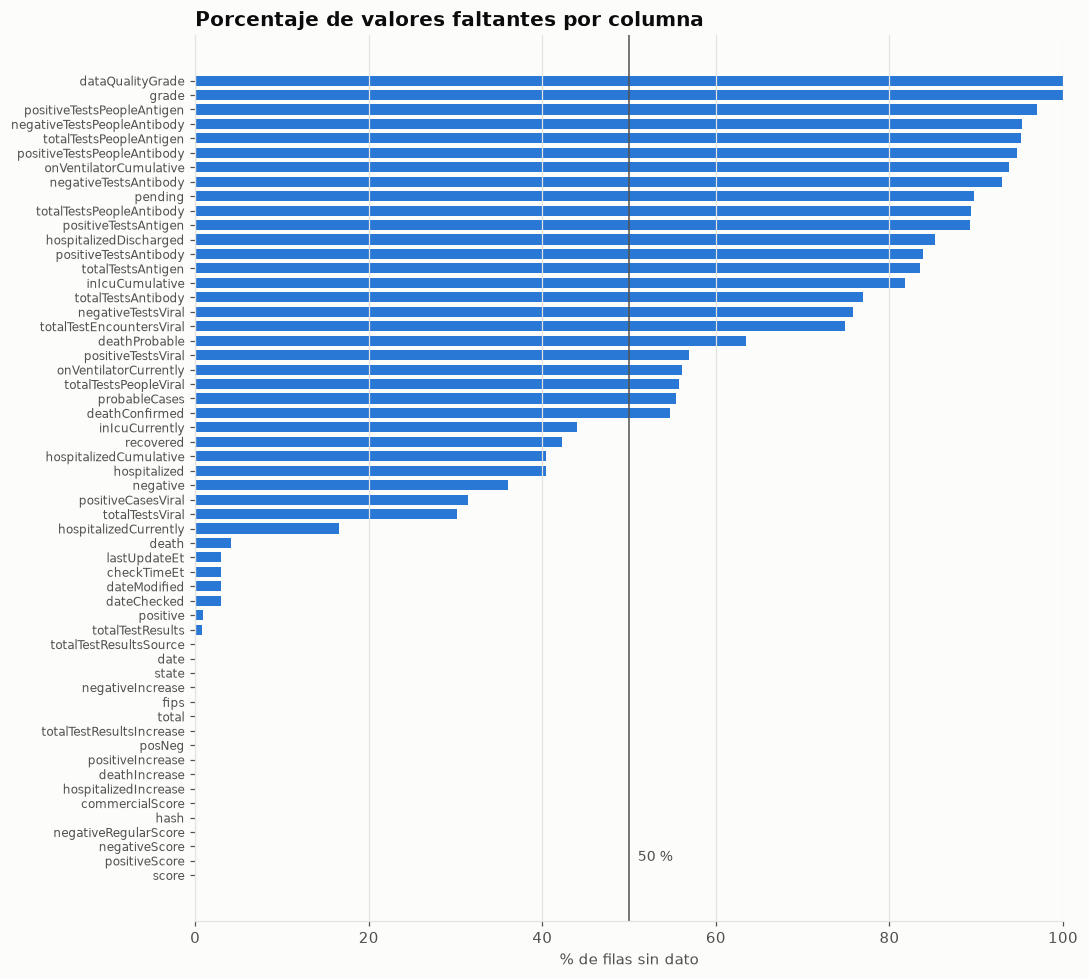

Columnas con más del 80 % de nulos: 15
Columnas con más del 50 % de nulos: 24


In [6]:
nulos = (crudo.isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(nulos.index[::-1], nulos.values[::-1], color=AZUL, height=0.7)
ax.axvline(50, color=TEXTO_SUAVE, linewidth=1)
ax.text(51, 1, "50 %", color=TEXTO_SUAVE, fontsize=9)
ax.set_title("Porcentaje de valores faltantes por columna")
ax.set_xlabel("% de filas sin dato")
ax.set_xlim(0, 100)
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print(f"Columnas con más del 80 % de nulos: {(nulos > 80).sum()}")
print(f"Columnas con más del 50 % de nulos: {(nulos > 50).sum()}")

Casi la mitad de las columnas están vacías en más del 50 % de las filas. No es un error de descarga:
cada estado informaba de cosas distintas (unos de tests de antígenos, otros no; unos de pacientes en UCI,
otros no). **Decisión:** no imputamos estas columnas, porque inventaríamos más de la mitad de los datos;
las descartamos en el apartado 2.4 y nos centramos en las que casi todos los estados publicaban.

### 2.2 Duplicados

In [7]:
print("Filas idénticas:", crudo.duplicated().sum())
print("Más de una fila para el mismo estado y día:", crudo.duplicated(subset=["date", "state"]).sum())

Filas idénticas: 0
Más de una fila para el mismo estado y día: 0


No hay duplicados, ni filas idénticas ni dos registros del mismo estado el mismo día, así que no hay
nada que eliminar. Comprobar la pareja `date` + `state` es lo importante: es la clave natural de la tabla.

### 2.3 Tipos de datos: la fecha

In [8]:
datos = convertir_fecha(crudo)
print(datos["date"].dtype)
print("Desde", datos["date"].min().date(), "hasta", datos["date"].max().date())

datetime64[us]
Desde 2020-01-13 hasta 2021-03-07


`convertir_fecha` aplica `pd.to_datetime(df["date"].astype(str), format="%Y%m%d")`. Con la fecha como
fecha ya podemos ordenar, agrupar por mes y dibujar series temporales.

### 2.4 Columnas: cuáles quitamos y por qué

Nos quedamos con 15 de las 56 columnas. Las descartadas caen en cinco grupos:

In [9]:
descartadas = {
    "Vacías al 100 %": ["dataQualityGrade", "grade"],
    "Siempre valen 0 (la fuente las marcó como obsoletas)": [
        "commercialScore", "negativeRegularScore", "negativeScore", "positiveScore", "score"],
    "Repiten otra columna": ["total", "posNeg", "hospitalized"],
    "Metadatos técnicos de la API": [
        "hash", "lastUpdateEt", "dateModified", "checkTimeEt", "dateChecked"],
}
ya_listadas = {c for grupo in descartadas.values() for c in grupo}
descartadas["Demasiados nulos o unidades distintas según el estado"] = [
    c for c in crudo.columns if c not in COLUMNAS and c not in ya_listadas]

for motivo, columnas in descartadas.items():
    print(f"{motivo} ({len(columnas)}):")
    print("   ", ", ".join(columnas))

# Comprobaciones que respaldan los grupos
assert (crudo[descartadas["Siempre valen 0 (la fuente las marcó como obsoletas)"]] == 0).all().all()
assert (crudo["posNeg"] == crudo["positive"].fillna(0) + crudo["negative"].fillna(0)).all()
assert (crudo["total"] == crudo["posNeg"] + crudo["pending"].fillna(0)).all()
assert crudo["hospitalized"].equals(crudo["hospitalizedCumulative"])

Vacías al 100 % (2):
    dataQualityGrade, grade
Siempre valen 0 (la fuente las marcó como obsoletas) (5):
    commercialScore, negativeRegularScore, negativeScore, positiveScore, score
Repiten otra columna (3):
    total, posNeg, hospitalized
Metadatos técnicos de la API (5):
    hash, lastUpdateEt, dateModified, checkTimeEt, dateChecked
Demasiados nulos o unidades distintas según el estado (26):
    probableCases, negative, pending, hospitalizedCumulative, inIcuCumulative, onVentilatorCumulative, hospitalizedDischarged, totalTestsViral, positiveTestsViral, negativeTestsViral, positiveCasesViral, deathConfirmed, deathProbable, totalTestEncountersViral, totalTestsPeopleViral, totalTestsAntibody, positiveTestsAntibody, negativeTestsAntibody, totalTestsPeopleAntibody, positiveTestsPeopleAntibody, negativeTestsPeopleAntibody, totalTestsPeopleAntigen, positiveTestsPeopleAntigen, totalTestsAntigen, positiveTestsAntigen, negativeIncrease


- **Constantes y vacías:** no aportan nada; una columna que siempre vale 0 no puede explicar nada.
- **Repetidas:** `posNeg` es exactamente `positive + negative`, y `total` es `posNeg + pending` (las `assert`
  lo comprueban); la propia fuente las daba por obsoletas. `hospitalized` es una copia de `hospitalizedCumulative`.
- **Metadatos:** dicen cuándo se actualizó el registro, no qué pasó ese día.
- **Desglose de tests** (víricos, antígenos, anticuerpos, por personas o por muestras): cada estado contaba
  con una unidad distinta y casi todas superan el 50 % de nulos. `totalTestResults` ya unifica los tests
  de cada estado y `totalTestResultsSource` dice qué unidad se usó; con eso nos basta.

El resto lo **renombramos al castellano** en `snake_case` para que el análisis se lea mejor:

In [10]:
datos = seleccionar_y_renombrar(datos)
pd.DataFrame({"original": list(COLUMNAS), "nuevo nombre": list(COLUMNAS.values())})

,original,nuevo nombre
0,date,fecha
1,state,estado
2,fips,fips
3,positive,casos_acum
4,positiveIncrease,casos_nuevos
5,death,muertes_acum
6,deathIncrease,muertes_nuevas
7,totalTestResults,tests_acum
8,totalTestResultsIncrease,tests_nuevos
9,totalTestResultsSource,fuente_tests


### 2.5 Incrementos diarios negativos

Un estado no puede tener "casos nuevos negativos". Son **correcciones**: el estado detectaba duplicados o
errores de días anteriores y los restaba de golpe del recuento diario.

In [11]:
diarias = ["casos_nuevos", "muertes_nuevas", "tests_nuevos", "hospitalizados_nuevos"]
(datos[diarias] < 0).sum().rename("filas negativas").to_frame()

,filas negativas
casos_nuevos,24
muertes_nuevas,73
tests_nuevos,49
hospitalizados_nuevos,88


In [12]:
datos = marcar_correcciones(datos)
print(f"Filas marcadas como corrección: {datos['es_correccion'].sum()} "
      f"({datos['es_correccion'].mean():.1%} del total)")

Filas marcadas como corrección: 219 (1.1% del total)


**Decisión:** el valor negativo pasa a `NaN` y la fila queda marcada en `es_correccion`. No borramos la fila,
porque el resto de sus columnas (acumulados, hospitalizados) son válidas. Tampoco ponemos un 0, porque no
sabemos cuántos casos hubo de verdad ese día.

Son solo unas 220 filas (~1 %), así que no cambian las tendencias, pero sí estropearían histogramas y
mínimos. Los **acumulados no se tocan**: ya incorporan la corrección y son la cifra oficial a cierre.

### 2.6 Estados y territorios

Hay 56 códigos: 50 estados, Washington D. C. y 5 territorios (Samoa Americana, Guam, Islas Marianas del Norte,
Puerto Rico e Islas Vírgenes). Los marcamos para poder separarlos cuando haga falta.

In [13]:
datos = marcar_territorios(datos).sort_values(["estado", "fecha"]).reset_index(drop=True)
datos["es_territorio"].value_counts().rename({False: "estados + DC", True: "territorios"}).to_frame("filas")

,filas
es_territorio,
estados + DC,18995
territorios,1785


### 2.7 Faltantes que quedan en las columnas elegidas

Las columnas que conservamos tienen pocos nulos, salvo las de hospital:

In [14]:
(datos.isna().mean() * 100).round(1).sort_values(ascending=False).to_frame("% nulos")

,% nulos
ventilador_actuales,56.1
uci_actuales,44.0
recuperados,42.2
hospitalizados_actuales,16.6
muertes_acum,4.1
casos_acum,0.9
tests_acum,0.8
hospitalizados_nuevos,0.4
muertes_nuevas,0.4
tests_nuevos,0.2


- **`casos_acum`, `muertes_acum`, `tests_acum` (≤ 4 %)**: los nulos están en los primeros días, antes de que
  cada estado empezara a publicar. No los imputamos: un acumulado vacío al principio significa "aún no se
  informaba", no "cero".
- **`hospitalizados_actuales` (17 %)**: igual, sobre todo en marzo y abril de 2020. Al sumar el total
  nacional, pandas ignora los `NaN`, así que **en la primavera de 2020 la cifra nacional se queda corta**.
  Lo tendremos en cuenta al interpretarla.
- **`uci_actuales`, `ventilador_actuales`, `recuperados` (40-56 %)**: las conservamos como referencia,
  pero no sacamos conclusiones de ellas.

### 2.8 Datos sospechosos que no corregimos (por ahora)

In [15]:
mas_positivos_que_tests = datos["casos_acum"] > datos["tests_acum"]
print(f"Filas con más positivos acumulados que tests acumulados: {mas_positivos_que_tests.sum()}")
datos.loc[mas_positivos_que_tests, "estado"].value_counts().head()

Filas con más positivos acumulados que tests acumulados: 59


estado
WA    38
MI    15
GA     6
Name: count, dtype: int64

Es imposible tener más positivos que tests. Ocurre en estados que contaban los positivos por *personas* y
los tests por *muestras* (o al revés), o que sumaban casos probables sin test. Son pocas filas y no afectan
a las preguntas de este notebook, así que **las dejamos documentadas** y no las corregimos.

In [16]:
RUTA_LIMPIOS.parent.mkdir(parents=True, exist_ok=True)
datos.to_csv(RUTA_LIMPIOS, index=False)
print("Guardado:", RUTA_LIMPIOS.relative_to(RAIZ), datos.shape)

Guardado:

 data\processed\covid_estados_limpio.csv (20780, 17)


## 3. Análisis univariado

Para mirar el país en conjunto creamos una **tabla nacional** que suma todos los estados y territorios
cada día. Para comparar estados usamos la **última fila de cada estado** (7 de marzo de 2021), cuyos
acumulados son los totales finales.

In [17]:
nacional = datos.groupby("fecha")[["casos_nuevos", "muertes_nuevas", "tests_nuevos",
                                   "hospitalizados_actuales"]].sum(min_count=1)
nacional_7d = nacional.rolling(7).mean()   # media de 7 días para suavizar el efecto fin de semana

final = datos.sort_values("fecha").groupby("estado").tail(1).set_index("estado")
print("Fecha de cierre de cada estado:", final["fecha"].unique())

Fecha de cierre de cada estado: <DatetimeArray>
['2021-03-07 00:00:00']
Length: 1, dtype: datetime64[us]


### 3.1 Casos nuevos por estado y día

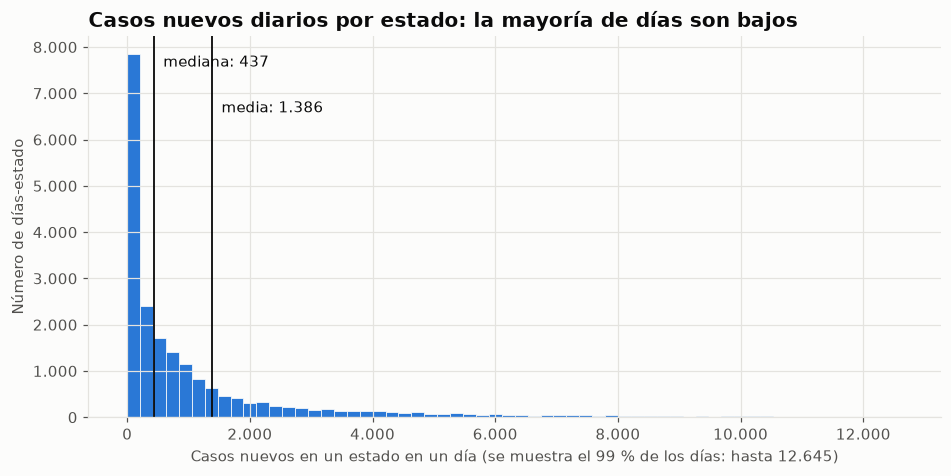

count    20756.0
mean      1386.0
std       3024.0
min          0.0
25%         66.0
50%        437.0
75%       1337.0
max      71734.0
Name: casos_nuevos, dtype: float64

In [18]:
casos = datos["casos_nuevos"].dropna()
p99 = casos.quantile(0.99)

fig, ax = plt.subplots()
ax.hist(casos[casos <= p99], bins=60, color=AZUL, edgecolor="#fcfcfb", linewidth=0.5)
for valor, nombre, desplazamiento in [(casos.median(), "mediana", 150), (casos.mean(), "media", 150)]:
    ax.axvline(valor, color=TEXTO, linewidth=1.2)
    ax.text(valor + desplazamiento, ax.get_ylim()[1] * (0.92 if nombre == "mediana" else 0.8),
            f"{nombre}: {valor:,.0f}".replace(",", "."), color=TEXTO)
ax.set_title("Casos nuevos diarios por estado: la mayoría de días son bajos")
limite = f"{p99:,.0f}".replace(",", ".")
ax.set_xlabel(f"Casos nuevos en un estado en un día (se muestra el 99 % de los días: hasta {limite})")
ax.set_ylabel("Número de días-estado")
ax.xaxis.set_major_formatter(miles)
ax.yaxis.set_major_formatter(miles)
plt.show()

datos["casos_nuevos"].describe().round(0)

Distribución **muy sesgada a la derecha**: la mediana es de unos 440 casos al día, pero la media se va a casi
1.400 y el máximo supera los 70.000 (ese 1 % de días más altos ni cabe en el gráfico). Pocos días de
estados grandes en pleno pico tiran de la media hacia arriba. Por eso, en este dataset la **mediana describe mejor un "día típico"** que la media.

### 3.2 Muertes nuevas por estado y día

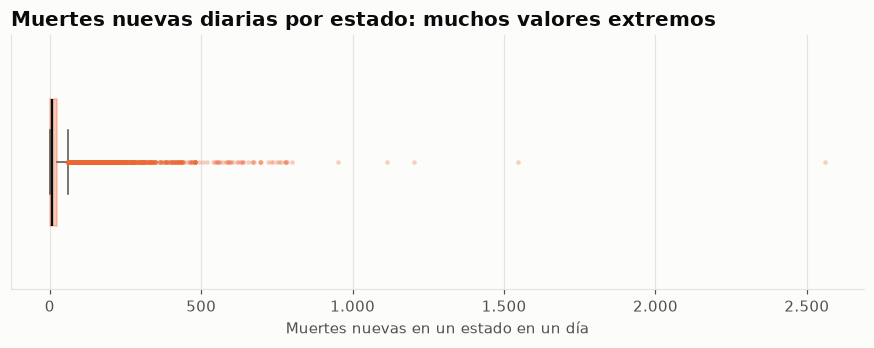

Mediana: 6 | Q1: 0 | Q3: 24
El 75 % de los días-estado tuvo 24 muertes o menos


In [19]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.boxplot(datos["muertes_nuevas"].dropna(), orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops=dict(facecolor=NARANJA, color=NARANJA, alpha=0.35),
           medianprops=dict(color=TEXTO, linewidth=1.5),
           whiskerprops=dict(color=TEXTO_SUAVE), capprops=dict(color=TEXTO_SUAVE),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=NARANJA,
                           markeredgecolor="none", alpha=0.3))
ax.set_title("Muertes nuevas diarias por estado: muchos valores extremos")
ax.set_xlabel("Muertes nuevas en un estado en un día")
ax.set_yticks([])
ax.xaxis.set_major_formatter(miles)
plt.show()

q1, q3 = datos["muertes_nuevas"].quantile([0.25, 0.75])
print(f"Mediana: {datos['muertes_nuevas'].median():.0f} | Q1: {q1:.0f} | Q3: {q3:.0f}")
print(f"El 75 % de los días-estado tuvo {q3:.0f} muertes o menos")

La caja es estrechísima (la mitad central de los días está entre 0 y 24 muertes) y a la derecha aparece una nube
de puntos extremos. Muchos son reales (Nueva York superó las 750 muertes diarias varios días de abril de 2020);
pero los más alejados son **atrasos de notificación**: días en que un estado sumó de golpe muertes de semanas
anteriores. Los veremos en la tabla de abajo y los analizaremos a fondo en el nivel medio con el rango intercuartílico.

In [20]:
datos.nlargest(6, "muertes_nuevas")[["fecha", "estado", "muertes_nuevas"]]

,fecha,estado,muertes_nuevas
14421,2021-02-12,OH,2559.0
6616,2021-02-04,IN,1546.0
14422,2021-02-13,OH,1204.0
2184,2021-02-25,CA,1114.0
13772,2020-05-07,NY,951.0
13744,2020-04-09,NY,799.0


Ohio sumó **2.559 muertes el 12 de febrero de 2021** e Indiana 1.546 el 4 de febrero: ninguno de los dos
estaba en su peor momento, sino revisando certificados de defunción atrasados. Estos días hinchan los datos
diarios, y es una de las razones para usar la **media de 7 días** en las series temporales.

### 3.3 Cómo contaba cada estado los tests

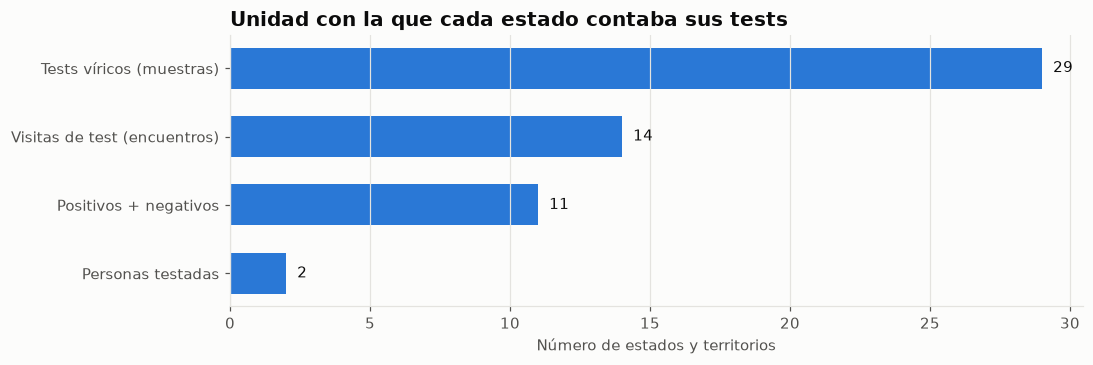

In [21]:
etiquetas = {
    "totalTestsViral": "Tests víricos (muestras)",
    "totalTestEncountersViral": "Visitas de test (encuentros)",
    "posNeg": "Positivos + negativos",
    "totalTestsPeopleViral": "Personas testadas",
}
fuentes = final["fuente_tests"].map(etiquetas).value_counts()

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.barh(fuentes.index[::-1], fuentes.values[::-1], color=AZUL, height=0.6)
for y, valor in enumerate(fuentes.values[::-1]):
    ax.text(valor + 0.4, y, str(valor), va="center", color=TEXTO)
ax.set_title("Unidad con la que cada estado contaba sus tests")
ax.set_xlabel("Número de estados y territorios")
ax.grid(axis="y", visible=False)
plt.show()

No todos los estados contaban lo mismo: la mitad informaba de **muestras analizadas**, una parte de **visitas**
(una persona puede dar varias muestras) y otra de **positivos + negativos**. Así que comparar el número de tests
entre estados hay que hacerlo con cuidado: no siempre se cuenta lo mismo.

## 4. Análisis bivariado

### 4.1 Tiempo y casos/muertes nuevos (pregunta 1)

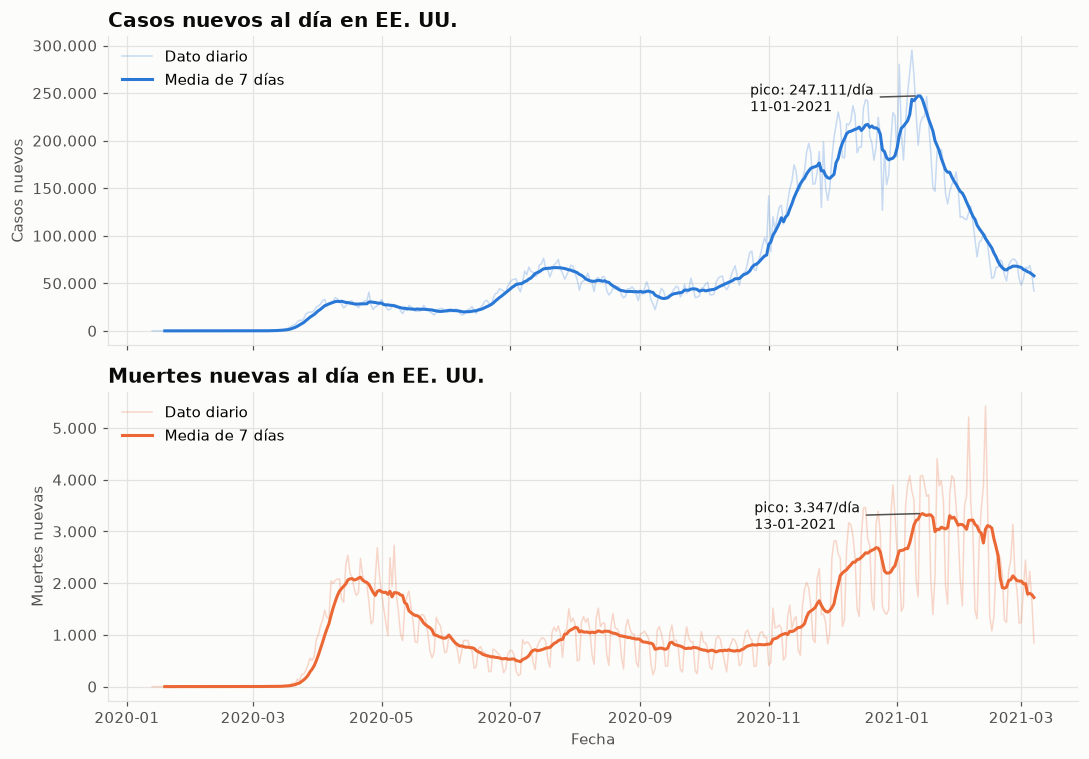

In [22]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax1.plot(nacional.index, nacional["casos_nuevos"], color=AZUL, alpha=0.25, linewidth=1, label="Dato diario")
ax1.plot(nacional_7d.index, nacional_7d["casos_nuevos"], color=AZUL, label="Media de 7 días")
ax1.set_title("Casos nuevos al día en EE. UU.")
ax1.set_ylabel("Casos nuevos")
ax1.yaxis.set_major_formatter(miles)
ax1.legend(loc="upper left")

ax2.plot(nacional.index, nacional["muertes_nuevas"], color=NARANJA, alpha=0.25, linewidth=1, label="Dato diario")
ax2.plot(nacional_7d.index, nacional_7d["muertes_nuevas"], color=NARANJA, label="Media de 7 días")
ax2.set_title("Muertes nuevas al día en EE. UU.")
ax2.set_ylabel("Muertes nuevas")
ax2.set_xlabel("Fecha")
ax2.yaxis.set_major_formatter(miles)
ax2.legend(loc="upper left")

for ax, col in [(ax1, "casos_nuevos"), (ax2, "muertes_nuevas")]:
    pico = nacional_7d[col].idxmax()
    ax.annotate(f"pico: {nacional_7d[col].max():,.0f}/día\n{pico:%d-%m-%Y}".replace(",", "."),
                xy=(pico, nacional_7d[col].max()), xytext=(-110, -10), textcoords="offset points",
                color=TEXTO, fontsize=9, arrowprops=dict(arrowstyle="-", color=TEXTO_SUAVE))

plt.tight_layout()
plt.show()

In [23]:
olas = {"1.ª ola (abril 2020)": "2020-04", "2.ª ola (julio 2020)": "2020-07", "3.ª ola (enero 2021)": "2021-01"}
pd.DataFrame({
    ola: {"máx. casos/día (media 7 d)": nacional_7d.loc[mes, "casos_nuevos"].max(),
          "máx. muertes/día (media 7 d)": nacional_7d.loc[mes, "muertes_nuevas"].max()}
    for ola, mes in olas.items()
}).T.round(0)

,máx. casos/día (media 7 d),máx. muertes/día (media 7 d)
1.ª ola (abril 2020),31129.0,2115.0
2.ª ola (julio 2020),66564.0,1119.0
3.ª ola (enero 2021),247111.0,3347.0


Hay **tres olas** claras. La de invierno de 2020-2021 es con diferencia la peor: casi **250.000 casos diarios**
(media de 7 días) a mediados de enero de 2021, unas 8 veces la primera ola. Las muertes también tocan techo en
enero (unas 3.300 diarias). El pico suelto de más de 5.000 muertes en febrero es el atraso de Ohio del apartado 3.2.

Llama la atención que la **primera ola tuvo dos tercios de las muertes de la tercera con 8 veces menos casos**.
Es poco probable que el virus fuera 8 veces más letal: en la primavera de 2020 se hacían muy pocos tests y solo
se detectaban los casos graves, así que los casos reales eran muchos más de los que se contaban.

### 4.2 Estado y casos/muertes acumulados (pregunta 2)

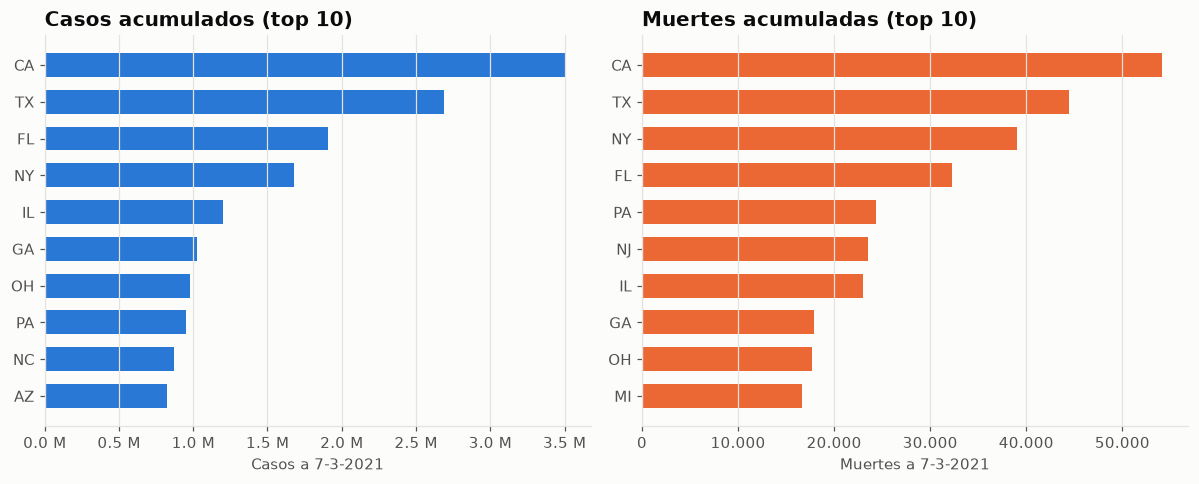

Total EE. UU.: 28.756.489 casos y 515.151 muertes
Los 5 estados con más casos suman el 38% del total


In [24]:
top_casos = final["casos_acum"].nlargest(10)[::-1]
top_muertes = final["muertes_acum"].nlargest(10)[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ax1.barh(top_casos.index, top_casos.values, color=AZUL, height=0.65)
ax1.set_title("Casos acumulados (top 10)")
ax1.set_xlabel("Casos a 7-3-2021")
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f} M"))

ax2.barh(top_muertes.index, top_muertes.values, color=NARANJA, height=0.65)
ax2.set_title("Muertes acumuladas (top 10)")
ax2.set_xlabel("Muertes a 7-3-2021")
ax2.xaxis.set_major_formatter(miles)

for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

cuota_top5 = final["casos_acum"].nlargest(5).sum() / final["casos_acum"].sum()
print(f"Total EE. UU.: {final['casos_acum'].sum():,.0f} casos y {final['muertes_acum'].sum():,.0f} muertes"
      .replace(",", "."))
print(f"Los 5 estados con más casos suman el {cuota_top5:.0%} del total")

California, Texas, Florida, Nueva York e Illinois concentran el **38 % de los casos** del país.
Pero son también los estados más poblados, así que este ranking dice sobre todo **dónde vive más gente**,
no dónde golpeó más fuerte el virus. Para compararlos con justicia habrá que dividir por la población
(casos por cada 100.000 habitantes), cruzando con una segunda fuente de datos en el nivel avanzado.

Un detalle: **Nueva York es 4.º en casos y 3.º en muertes**. Le tocó la primera ola, cuando apenas se hacían
tests (muchos casos sin contar) y aún no se sabía cómo tratar la enfermedad.

### 4.3 Hospitalizados y muertes (pregunta 3)

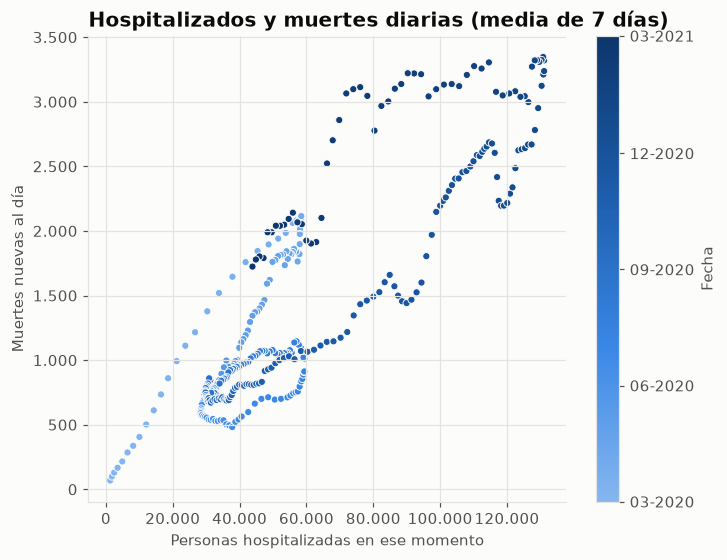

Correlación hospitalizados - muertes: 0.87


In [25]:
pares = nacional_7d[["hospitalizados_actuales", "muertes_nuevas"]].dropna()

# Escala de un solo tono (azul claro -> oscuro) sin los pasos casi blancos, que se perderían en el fondo.
from matplotlib.colors import LinearSegmentedColormap
azules = LinearSegmentedColormap.from_list("azules", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

fig, ax = plt.subplots(figsize=(7, 5.5))
puntos = ax.scatter(pares["hospitalizados_actuales"], pares["muertes_nuevas"],
                    c=pares.index.map(pd.Timestamp.toordinal), cmap=azules, s=22,
                    edgecolors="#fcfcfb", linewidths=0.6)
barra = fig.colorbar(puntos, ax=ax)
ticks = pd.date_range(pares.index.min(), pares.index.max(), periods=5)
barra.set_ticks([t.toordinal() for t in ticks])
barra.set_ticklabels([f"{t:%m-%Y}" for t in ticks])
barra.set_label("Fecha")
ax.set_title("Hospitalizados y muertes diarias (media de 7 días)")
ax.set_xlabel("Personas hospitalizadas en ese momento")
ax.set_ylabel("Muertes nuevas al día")
ax.xaxis.set_major_formatter(miles)
ax.yaxis.set_major_formatter(miles)
plt.show()

print(f"Correlación hospitalizados - muertes: {pares.corr().iloc[0, 1]:.2f}")

Relación **fuerte y positiva** (correlación de 0,87): cuantas más personas hay en el hospital, más muertes al día.
El color muestra el paso del tiempo y deja ver dos cosas más:

- Los puntos más claros (primavera de 2020) quedan **por encima** de los del verano: más muertes para el mismo
  número de hospitalizados. Encaja con que el recuento de hospitalizados de entonces se quedaba corto (apartado 2.7)
  y con que los tratamientos mejoraron con los meses.
- La ola de invierno dibuja un **bucle**: al subir, las muertes van por debajo; al bajar (los puntos más oscuros,
  febrero de 2021), los hospitalizados caen rápido pero las muertes siguen altas. **Las muertes van con retraso
  respecto a los ingresos.** Lo medimos en el siguiente apartado.

### 4.4 Casos y muertes: ¿con cuánto retraso? (pregunta 3)

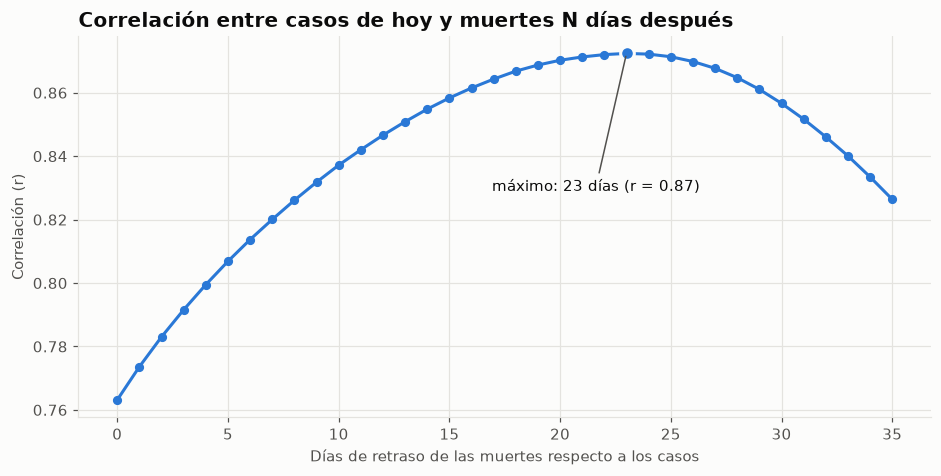

In [26]:
retrasos = range(0, 36)
correlaciones = pd.Series(
    [nacional_7d["casos_nuevos"].corr(nacional_7d["muertes_nuevas"].shift(-d)) for d in retrasos],
    index=retrasos)
mejor = correlaciones.idxmax()

fig, ax = plt.subplots()
ax.plot(correlaciones.index, correlaciones.values, color=AZUL, marker="o", markersize=5)
ax.scatter([mejor], [correlaciones[mejor]], s=80, color=AZUL, edgecolors="#fcfcfb", linewidths=2, zorder=3)
ax.annotate(f"máximo: {mejor} días (r = {correlaciones[mejor]:.2f})",
            xy=(mejor, correlaciones[mejor]), xytext=(-20, -90), textcoords="offset points", ha="center",
            color=TEXTO, arrowprops=dict(arrowstyle="-", color=TEXTO_SUAVE))
ax.set_title("Correlación entre casos de hoy y muertes N días después")
ax.set_xlabel("Días de retraso de las muertes respecto a los casos")
ax.set_ylabel("Correlación (r)")
plt.show()

Si comparamos los casos con las muertes **del mismo día**, la correlación es de 0,76. Si las desplazamos, sube
hasta un máximo de 0,87 con **23 días de retraso**, algo más de tres semanas. Tiene sentido: entre el contagio, el diagnóstico, el
ingreso y el fallecimiento pasan varias semanas.

**Lectura práctica:** una subida de casos anuncia una subida de muertes unas tres semanas después.

## 5. Respuestas a las preguntas de partida

**1. ¿Cómo evolucionó la pandemia y cuándo fue el peor momento?**
En tres olas: primavera de 2020 (centrada en el noreste), verano de 2020 (sur y oeste) e invierno de
2020-2021. La tercera fue la peor con diferencia: en enero de 2021 se llegó a casi 250.000 casos y unas 3.300
muertes al día, con más de 130.000 personas hospitalizadas a la vez.

**2. ¿Qué estados acumularon más casos y más muertes?**
California, Texas, Florida, Nueva York e Illinois, que suman el 38 % de los casos. En muertes, Nueva York sube
al tercer puesto por el golpe de la primera ola. Son cifras absolutas y reflejan sobre todo el tamaño de
cada estado; queda pendiente normalizarlas por población.

**3. ¿Las hospitalizaciones y los casos anticipan las muertes?**
Sí. Hospitalizados y muertes diarias van muy de la mano (r = 0,87), y los casos anticipan las muertes con
algo más de tres semanas de retraso (23 días). Una subida de casos es una alarma con tiempo suficiente para reaccionar en los hospitales.

**Limitaciones**

- Cifras absolutas, sin normalizar por población.
- En la primavera de 2020 se hacían pocos tests: los casos reales de la primera ola eran muchos más que los contados.
- Cada estado contaba los tests y los hospitalizados a su manera; hay unas 220 correcciones y 59 filas
  incoherentes (más positivos que tests) que dejamos documentadas.